# Five-species experiments: results and conclusions

This report brings together the two completed experiments since
[COMP9991 Report (9)](../../COMP9991_Report%20%289%29.pdf):

1. **The larger five-species run:** human, mouse lemur, mouse, frog and zebrafish,
   using 300 macrogenes, 384 hidden dimensions and 384 embedding dimensions.
2. **The strict cell holdout:** the same five species, using the original
   200/256/256 architecture, with 10% of each species excluded from the entire fitted pipeline.

**The main finding:** InfoNCE remains the strongest label-free method for species
integration among those tested, and it retains most of its performance on held-out
cells. Its absolute held-out label accuracy remains below the supervised baseline.
MMD and OT retain strong annotation agreement with much weaker species mixing.

Run All rebuilds this report locally from saved CSV/JSON records and PNG figures.
The notebook performs plotting and table calculations only. It does not load models,
run inference, compute neighbours, fit UMAP or contact the cloud. The original
experiment artifacts are read without modification; regenerated report figures go
to `out/five_species_experiment_report/`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import sys

os.environ.setdefault('MPLCONFIGDIR', '/tmp/macrogenes-matplotlib')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'scripts/execute_saturn_notebook.py').is_file())
ORIGINAL = ROOT / 'out/human_monkey_mouse_benchmark_walkthrough'
LARGER = ROOT / 'out/downloaded_human_monkey_mouse_frog_fish_jax_gpu_exact'
HOLDOUT = ROOT / 'out/human_monkey_mouse_frog_fish_jax_cell_holdout'
REPORT = ROOT / 'out/five_species_experiment_report'
ASSETS = REPORT / 'report_assets'
ASSETS.mkdir(parents=True, exist_ok=True)

TRIALS = ['baseline', 'infonce', 'mmd', 'ot']
NAMES = {'baseline': 'Supervised baseline', 'infonce': 'InfoNCE', 'mmd': 'MMD', 'ot': 'Partial OT'}
COLORS = dict(zip(TRIALS, ['#2563eb', '#d97706', '#059669', '#9333ea']))
SPECIES = {'h_sapiens': 'Human', 'm_murinus': 'Mouse lemur', 'm_musculus': 'Mouse',
           'x_laevis': 'Frog', 'd_rerio': 'Zebrafish'}
inputs = {}

def record_input(path):
    path = Path(path)
    data = path.read_bytes()
    inputs[path.relative_to(ROOT).as_posix()] = {
        'sha256': hashlib.sha256(data).hexdigest(), 'size': len(data)}
    return data

def load_json(path):
    return json.loads(record_input(path))

def load_csv(path):
    import io
    return pd.read_csv(io.BytesIO(record_input(path)))

def comparison(path):
    frame = load_csv(path)
    assert frame.trial.is_unique and set(frame.trial) == set(TRIALS)
    return frame.set_index('trial').loc[TRIALS]

def saved_figure(path):
    display(Image(data=record_input(path)))

def save_figure(figure, stem):
    for extension in ('png', 'pdf'):
        figure.savefig(ASSETS / f'{stem}.{extension}', dpi=170, bbox_inches='tight')
    plt.close(figure)
    display(Image(filename=str(ASSETS / f'{stem}.png')))

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'pdf.fonttype': 42, 'ps.fonttype': 42})

original = comparison(ORIGINAL / 'comparison.csv')
larger = comparison(LARGER / 'comparison.csv')
holdout_training = comparison(HOLDOUT / 'run/comparison.csv')
original_artifact = load_json(ORIGINAL / 'shared/artifact_metadata.json')
original_info = load_json(ORIGINAL / 'infonce/run_summary.json')
larger_record = load_json(LARGER / 'experiment_record.json')
larger_checkpoint = load_json(LARGER / 'baseline/metric_orbax/checkpoints/epoch_0030/metadata.json')
holdout_config = load_json(HOLDOUT / 'experiment_config.json')
holdout_checkpoint = load_json(HOLDOUT / 'foundation/baseline/metric_orbax/checkpoints/epoch_0030/metadata.json')
split_record = load_json(HOLDOUT / 'split/split_record.json')
diagnostic_record = load_json(HOLDOUT / 'diagnostics/summary.json')
generalization = load_csv(HOLDOUT / 'diagnostics/generalization.csv')
heldout_metrics = load_csv(HOLDOUT / 'heldout_metrics.csv')
larger_execution = load_json(LARGER / 'execution_result.json')
holdout_execution = load_json(HOLDOUT / 'execution_result.json')
acceptance = {'Larger full-data run': load_json(LARGER / 'acceptance.json'),
              'Cell-holdout run': load_json(HOLDOUT / 'run/acceptance.json')}

def architecture(metadata):
    hp = metadata['hyperparameters']
    return [hp['input_dim'], hp['hidden_dim'], hp['embed_dim']]

assert architecture(larger_checkpoint) == larger_record['scientific_configuration']['architecture'] == [300, 384, 384]
assert architecture(holdout_checkpoint) == [holdout_config[k] for k in ('num_macrogenes', 'hidden_dim', 'model_dim')] == [200, 256, 256]
assert not diagnostic_record['models_refitted'] and not diagnostic_record['umaps_refitted']
assert not diagnostic_record['selection_uses_test_labels'] and diagnostic_record['k'] == 15
assert larger_execution['execution_success'] and holdout_execution['execution_success']

split_counts = pd.DataFrame.from_dict(split_record['counts'], orient='index').loc[list(SPECIES)]
train_n, test_n = int(split_counts.train.sum()), int(split_counts.test.sum())
assert (train_n, test_n) == (133852, 14875)
assert int(larger_record['foundation']['cells']) == train_n + test_n == 148727
overall = generalization.loc[generalization.dimension == 'overall'].set_index('trial').loc[TRIALS]
assert overall.index.is_unique
assert (overall.train_queries == train_n).all() and (overall.test_queries == test_n).all()
for metric in ('label_same_neighbor_fraction', 'species_mixing_fraction'):
    np.testing.assert_allclose(overall[f'train_{metric}'], holdout_training[metric], atol=1e-8)
    cloud_scores = heldout_metrics.loc[heldout_metrics.species == 'all'].set_index('trial').loc[TRIALS, metric]
    np.testing.assert_allclose(overall[f'test_{metric}'], cloud_scores, atol=1e-8)
for metric in ('label_vote_accuracy', 'label_same_neighbor_fraction', 'species_mixing_fraction'):
    np.testing.assert_allclose(overall[f'gap_pp_{metric}'],
        100 * (overall[f'test_{metric}'] - overall[f'train_{metric}']), atol=1e-8)
print('Saved experiment configurations, split counts and aligned report metrics verified.')

Saved experiment configurations, split counts and aligned report metrics verified.


## What changed since the report?

The report studied 117,104 cells from three mammals. It concluded that InfoNCE
could approach supervised species integration while agreeing less closely with fine
cell-type labels. It also identified limited species diversity and the lack of
independent validation as important limitations (§5.4 and §6.2).

The experiments below address broader species coverage and unseen cells separately.
Their results are not a controlled comparison of embedding dimensions: architecture,
training duration, fitting population and, relative to the original report,
implementation also changed. The original report used **20 fine-tuning epochs**,
as confirmed by its author.

In [2]:
def completed_epochs(path):
    history = load_csv(path)
    epochs = pd.to_numeric(history['epoch'], errors='raise').to_numpy()
    assert len(epochs) > 0, f'Empty epoch history: {path}'
    np.testing.assert_array_equal(epochs, np.arange(1, len(epochs) + 1),
                                  err_msg=f'Non-contiguous epoch history: {path}')
    return len(epochs)

epoch_runs = [
    ('Larger five-species run', LARGER, LARGER, larger,
     LARGER / 'baseline/saturn_results/pretrain_losses.csv'),
    ('Five-species cell holdout', HOLDOUT / 'foundation', HOLDOUT / 'run', holdout_training,
     HOLDOUT / 'foundation/baseline/saturn_results/pretrain_losses.csv'),
]
original_training = {'pretraining_epochs': 20, 'fine_tuning_epochs': 20,
                     'source': 'Original report author confirmation in this conversation'}
pretraining_completed = {'Original report': original_training['pretraining_epochs']}
finetuning_completed = {'Original report': original_training['fine_tuning_epochs']}
epoch_rows = []
for name, foundation, trials_root, metrics, pretrain_path in epoch_runs:
    pretraining_completed[name] = completed_epochs(pretrain_path)
    pretrain_summary_path = foundation / 'baseline/saturn_results/pretrain_summary.json'
    if pretrain_summary_path.is_file():
        assert load_json(pretrain_summary_path)['epoch'] == pretraining_completed[name]
    counts = []
    for trial in TRIALS:
        history_path = trials_root / trial / 'history.csv'
        completed = completed_epochs(history_path)
        selected = int(metrics.loc[trial, 'selected_epoch'])
        assert 1 <= selected <= completed
        counts.append(completed)
        # Check exported histories against the underlying training log too.
        underlying = (foundation / 'baseline/saturn_results/metric_history.csv'
                      if trial == 'baseline' else trials_root / trial / 'metric_history.csv')
        assert completed_epochs(underlying) == completed
        summary_path = trials_root / trial / 'run_summary.json'
        if summary_path.is_file():
            summary = load_json(summary_path)
            assert int(summary['epochs']) == completed
            assert int(summary['selected_epoch']) == selected
        epoch_rows.append({'Experiment': name, 'Method': NAMES[trial],
            'Pretraining epochs completed': pretraining_completed[name],
            'Fine-tuning epochs completed': completed,
            'Reported checkpoint epoch': selected,
            'Pretraining history': pretrain_path.relative_to(ROOT).as_posix(),
            'Fine-tuning history': history_path.relative_to(ROOT).as_posix(),
            'Underlying fine-tuning history': underlying.relative_to(ROOT).as_posix()})
    assert len(set(counts)) == 1, f'Methods have different training durations: {name}'
    finetuning_completed[name] = counts[0]

assert pretraining_completed['Five-species cell holdout'] == holdout_config['pretrain_epochs']
assert finetuning_completed['Five-species cell holdout'] == holdout_config['metric_epochs']
assert finetuning_completed['Larger five-species run'] == larger_record['scientific_configuration']['epochs_per_objective']
assert int(larger_checkpoint['epoch']) == finetuning_completed['Larger five-species run']
assert int(holdout_checkpoint['epoch']) == finetuning_completed['Five-species cell holdout']
epoch_audit = pd.DataFrame(epoch_rows)
epoch_audit.to_csv(REPORT / 'epoch_audit.csv', index=False)

original_arch = [original_artifact['macrogene_dimension'],
                 original_info['configuration']['hidden_dim'], original_artifact['embedding_dimension']]
design = pd.DataFrame([
    ['Original report', 'Human, mouse lemur, mouse', int(original_artifact['cell_count']),
     'None', '/'.join(map(str, original_arch)), pretraining_completed['Original report'],
     finetuning_completed['Original report'], str(original_artifact['seed'])],
    ['Larger five-species run', 'Three mammals + frog + zebrafish', train_n + test_n,
     'None', '/'.join(map(str, architecture(larger_checkpoint))), pretraining_completed['Larger five-species run'],
     finetuning_completed['Larger five-species run'], str(larger_record['scientific_configuration']['seed'])],
    ['Five-species cell holdout', 'Three mammals + frog + zebrafish', train_n,
     f'{test_n:,}', '/'.join(map(str, architecture(holdout_checkpoint))),
     pretraining_completed['Five-species cell holdout'], finetuning_completed['Five-species cell holdout'],
     str(holdout_config['seed'])],
], columns=['Experiment', 'Species', 'Training cells', 'Held-out cells',
            'Macrogenes / hidden / embedding', 'Pretraining epochs completed',
            'Fine-tuning epochs completed per method', 'Seed']).set_index('Experiment')
display(design.style.format({'Training cells': '{:,}'}))
display(Markdown(f"""
**Original report:** **{finetuning_completed['Original report']} fine-tuning epochs**,
confirmed by the report's author.

**New experiments:** completed training and the evaluated checkpoint are separate counts.
The larger run selected InfoNCE epoch **{int(larger.loc['infonce', 'selected_epoch'])}**, and
the holdout selected epoch **{int(holdout_training.loc['infonce', 'selected_epoch'])}**.
Pretraining is a separate shared stage, completed before the four fine-tuning methods.

For the **two new experiments**, counts are derived from contiguous saved epoch
histories, with training logs, summaries and available metadata checked for agreement.
The per-method audit below covers those two experiments only;
the [CSV audit](../../out/five_species_experiment_report/epoch_audit.csv) records its source files.
"""))
display(epoch_audit.set_index(['Experiment', 'Method'])[
    ['Fine-tuning epochs completed', 'Reported checkpoint epoch']])

,Species,Training cells,Held-out cells,Macrogenes / hidden / embedding,Pretraining epochs completed,Fine-tuning epochs completed per method,Seed
Experiment,,,,,,,
Original report,"Human, mouse lemur, mouse","117,104",None,200/256/256,20,20,0
Larger five-species run,Three mammals + frog + zebrafish,"148,727",None,300/384/384,20,30,0
Five-species cell holdout,Three mammals + frog + zebrafish,"133,852","14,875",200/256/256,20,30,0



**Original report:** **20 fine-tuning epochs**,
confirmed by the report's author.

**New experiments:** completed training and the evaluated checkpoint are separate counts.
The larger run selected InfoNCE epoch **24**, and
the holdout selected epoch **27**.
Pretraining is a separate shared stage, completed before the four fine-tuning methods.

For the **two new experiments**, counts are derived from contiguous saved epoch
histories, with training logs, summaries and available metadata checked for agreement.
The per-method audit below covers those two experiments only;
the [CSV audit](../../out/five_species_experiment_report/epoch_audit.csv) records its source files.


Fine-tuning epochs completed  \
Experiment                Method                                              
Larger five-species run   Supervised baseline                            30   
                          InfoNCE                                        30   
                          MMD                                            30   
                          Partial OT                                     30   
Five-species cell holdout Supervised baseline                            30   
                          InfoNCE                                        30   
                          MMD                                            30   
                          Partial OT                                     30   

                                               Reported checkpoint epoch  
Experiment                Method                                          
Larger five-species run   Supervised baseline                         30  
                          InfoNCE                                     24  
                          MMD                                         30  
                          Partial OT                                  23  
Five-species cell holdout Supervised baseline                         30  
                          InfoNCE                                     27  
                          MMD                                         29  
                          Partial OT                                  30

## 1. Larger architecture across five species

All four methods shared the same enlarged pretrained foundation. Results are from
the baseline's epoch 30 and each label-free method's selected checkpoint, after all
methods completed 30 fine-tuning epochs. Selection remained label-free.

**Species mixing** is the fraction of the 15 nearest neighbours belonging to another
species. **Same-label neighbour agreement** is the fraction sharing the cell's label.
Agreement is not the same as majority-vote prediction accuracy, used later.
Both integration and preservation matter; mixing alone does not establish biological correctness.

,Selected epoch,Cross-species neighbours (%),Same-label neighbours (%),Fixed triplet loss
trial,,,,
Supervised baseline,30,8.95,83.30,0.0757
InfoNCE,24,12.76,76.21,0.0894
MMD,30,1.45,84.12,0.1771
Partial OT,23,1.59,83.70,0.0802


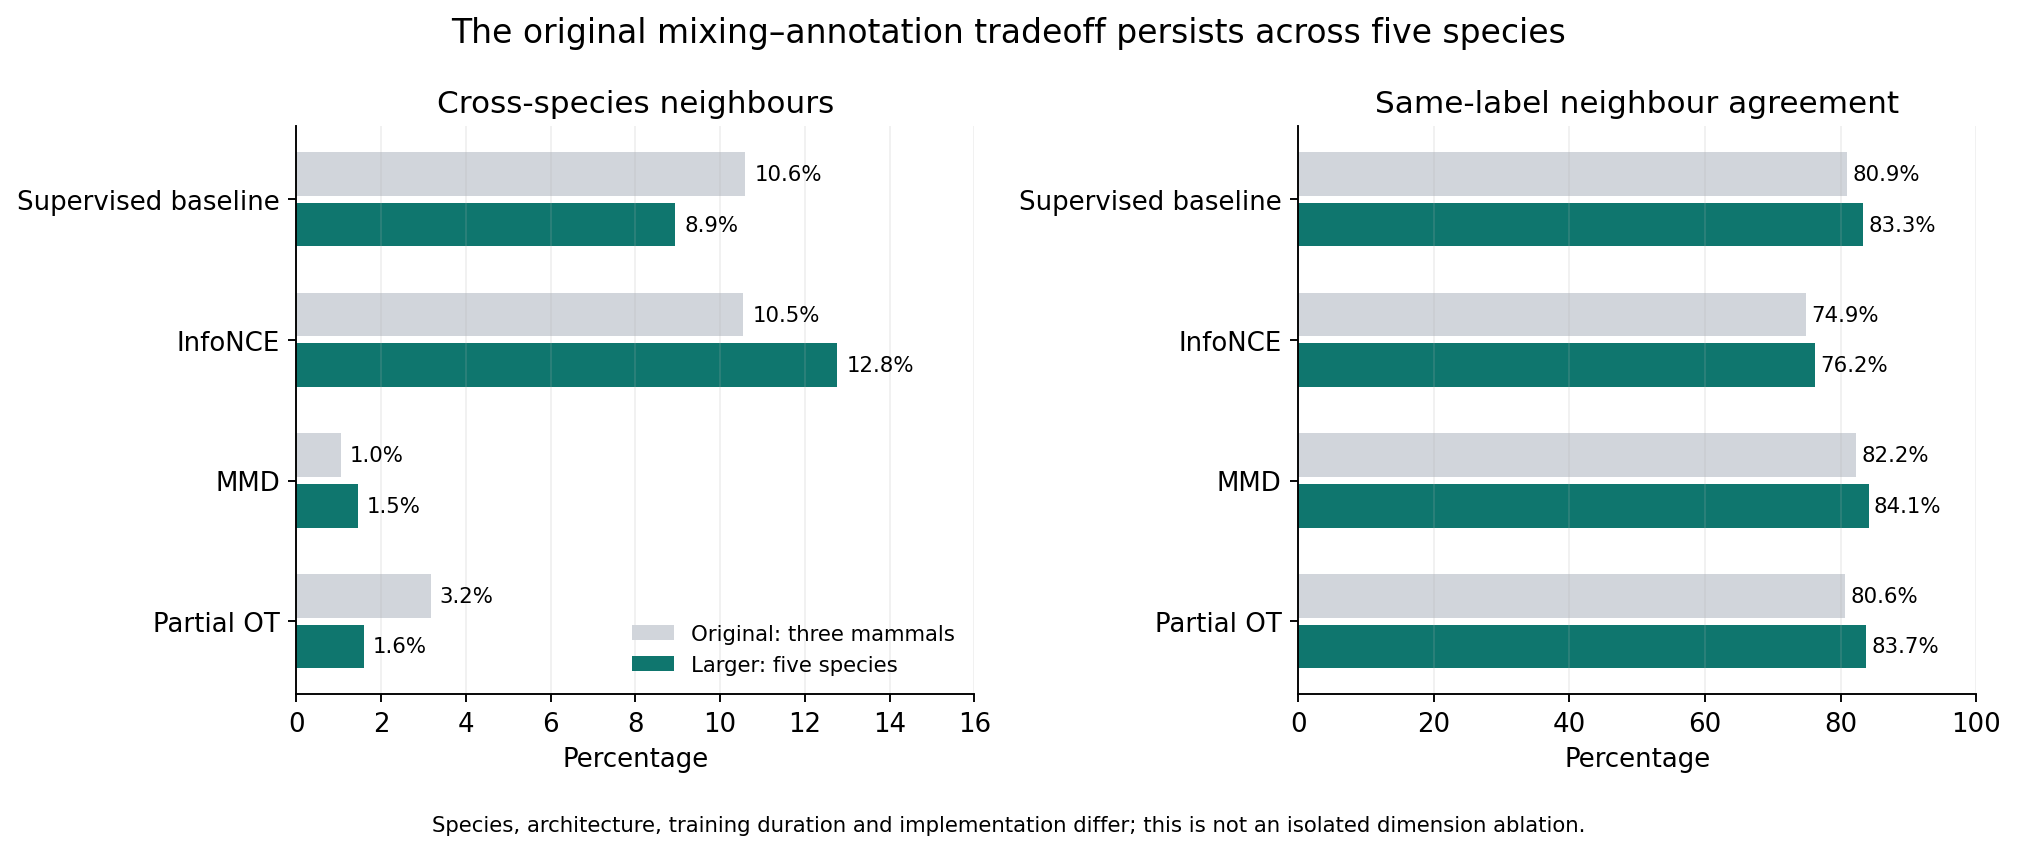

In [3]:
larger_table = pd.DataFrame({
    'Selected epoch': larger.selected_epoch,
    'Cross-species neighbours (%)': 100 * larger.species_mixing_fraction,
    'Same-label neighbours (%)': 100 * larger.label_same_neighbor_fraction,
    'Fixed triplet loss': larger.fixed_triplet_margin_loss,
}).rename(index=NAMES)
display(larger_table.style.format({'Selected epoch': '{:.0f}',
    'Cross-species neighbours (%)': '{:.2f}', 'Same-label neighbours (%)': '{:.2f}',
    'Fixed triplet loss': '{:.4f}'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
y = np.arange(len(TRIALS))
for ax, metric, title in zip(axes,
        ['species_mixing_fraction', 'label_same_neighbor_fraction'],
        ['Cross-species neighbours', 'Same-label neighbour agreement']):
    for offset, frame, color, label in [(-.18, original, '#d1d5db', 'Original: three mammals'),
                                      (.18, larger, '#0f766e', 'Larger: five species')]:
        values = 100 * frame[metric].to_numpy()
        ax.barh(y + offset, values, height=.31, color=color, label=label)
        for row, value in enumerate(values):
            ax.text(value + (.22 if metric.startswith('species') else .8), row + offset,
                    f'{value:.1f}%', va='center', fontsize=9)
    ax.set_yticks(y, [NAMES[t] for t in TRIALS])
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Percentage', xlim=(0, 16 if metric.startswith('species') else 100))
    ax.grid(axis='x', alpha=.18)
axes[0].legend(loc='lower right', frameon=False, fontsize=9)
fig.suptitle('The original mixing–annotation tradeoff persists across five species', fontsize=14)
fig.text(.5, -.04, 'Species, architecture, training duration and implementation differ; this is not an isolated dimension ablation.',
         ha='center', fontsize=9)
fig.tight_layout()
save_figure(fig, 'larger_run_vs_original_report')

In [4]:
big_info, big_base = larger.loc['infonce'], larger.loc['baseline']
display(Markdown(f"""
**Result.** InfoNCE achieved **{100*big_info.species_mixing_fraction:.1f}%** cross-species
neighbours, compared with **{100*big_base.species_mixing_fraction:.1f}%** for the supervised
baseline. Its same-label neighbour agreement was **{100*big_info.label_same_neighbor_fraction:.1f}%**,
compared with **{100*big_base.label_same_neighbor_fraction:.1f}%**. MMD and OT retained high
same-label agreement but mixed species much less.

**What this adds to the report.** The earlier pattern survives a larger architecture and
the addition of non-mammalian vertebrates. This strengthens the case for InfoNCE as a
useful label-agnostic alternative and repeats the distribution-matching methods' weak
integration under the tested configurations. It carries out the broader-species extension
proposed in §6.2.2.

The saved species breakdown also showed mixing for frog and zebrafish. However, the
original broad-category analysis still had no frog/fish ontology mappings. These results
therefore extend the **integration evidence**, while biological correctness still needs
external validation. They do not identify which architecture change caused any difference.
"""))


**Result.** InfoNCE achieved **12.8%** cross-species
neighbours, compared with **8.9%** for the supervised
baseline. Its same-label neighbour agreement was **76.2%**,
compared with **83.3%**. MMD and OT retained high
same-label agreement but mixed species much less.

**What this adds to the report.** The earlier pattern survives a larger architecture and
the addition of non-mammalian vertebrates. This strengthens the case for InfoNCE as a
useful label-agnostic alternative and repeats the distribution-matching methods' weak
integration under the tested configurations. It carries out the broader-species extension
proposed in §6.2.2.

The saved species breakdown also showed mixing for frog and zebrafish. However, the
original broad-category analysis still had no frog/fish ontology mappings. These results
therefore extend the **integration evidence**, while biological correctness still needs
external validation. They do not identify which architecture change caused any difference.


## 2. Do held-out cells retain training performance?

The split was deterministic and stratified by species only, rounding each species'
test count up. Test expression was excluded from fitted gene selection, centroids,
pretraining, teacher graphs, fine-tuning and checkpoint selection. Frozen encoders
then embedded the held-out counts, and test labels were joined for final evaluation.

The comparison below uses the same training reference for both populations.
Training queries exclude themselves. **Prediction accuracy** means the fraction of
queries whose majority label among 15 training neighbours matches the query label;
ties are resolved lexicographically. It is an evaluation rule, not a newly trained classifier.

,Held-out cells,Training cells
Human,"5,189","46,692"
Mouse lemur,"3,828","34,448"
Mouse,"2,695","24,252"
Frog,"2,944","26,493"
Zebrafish,219,"1,967"


,Training accuracy (%),Held-out accuracy (%),Accuracy drop (pp),Held-out cross-species neighbours (%)
trial,,,,
Supervised baseline,84.55,82.82,1.73,11.96
InfoNCE,81.34,81.09,0.25,11.45
MMD,86.21,85.10,1.11,2.91
Partial OT,85.88,85.43,0.46,2.74


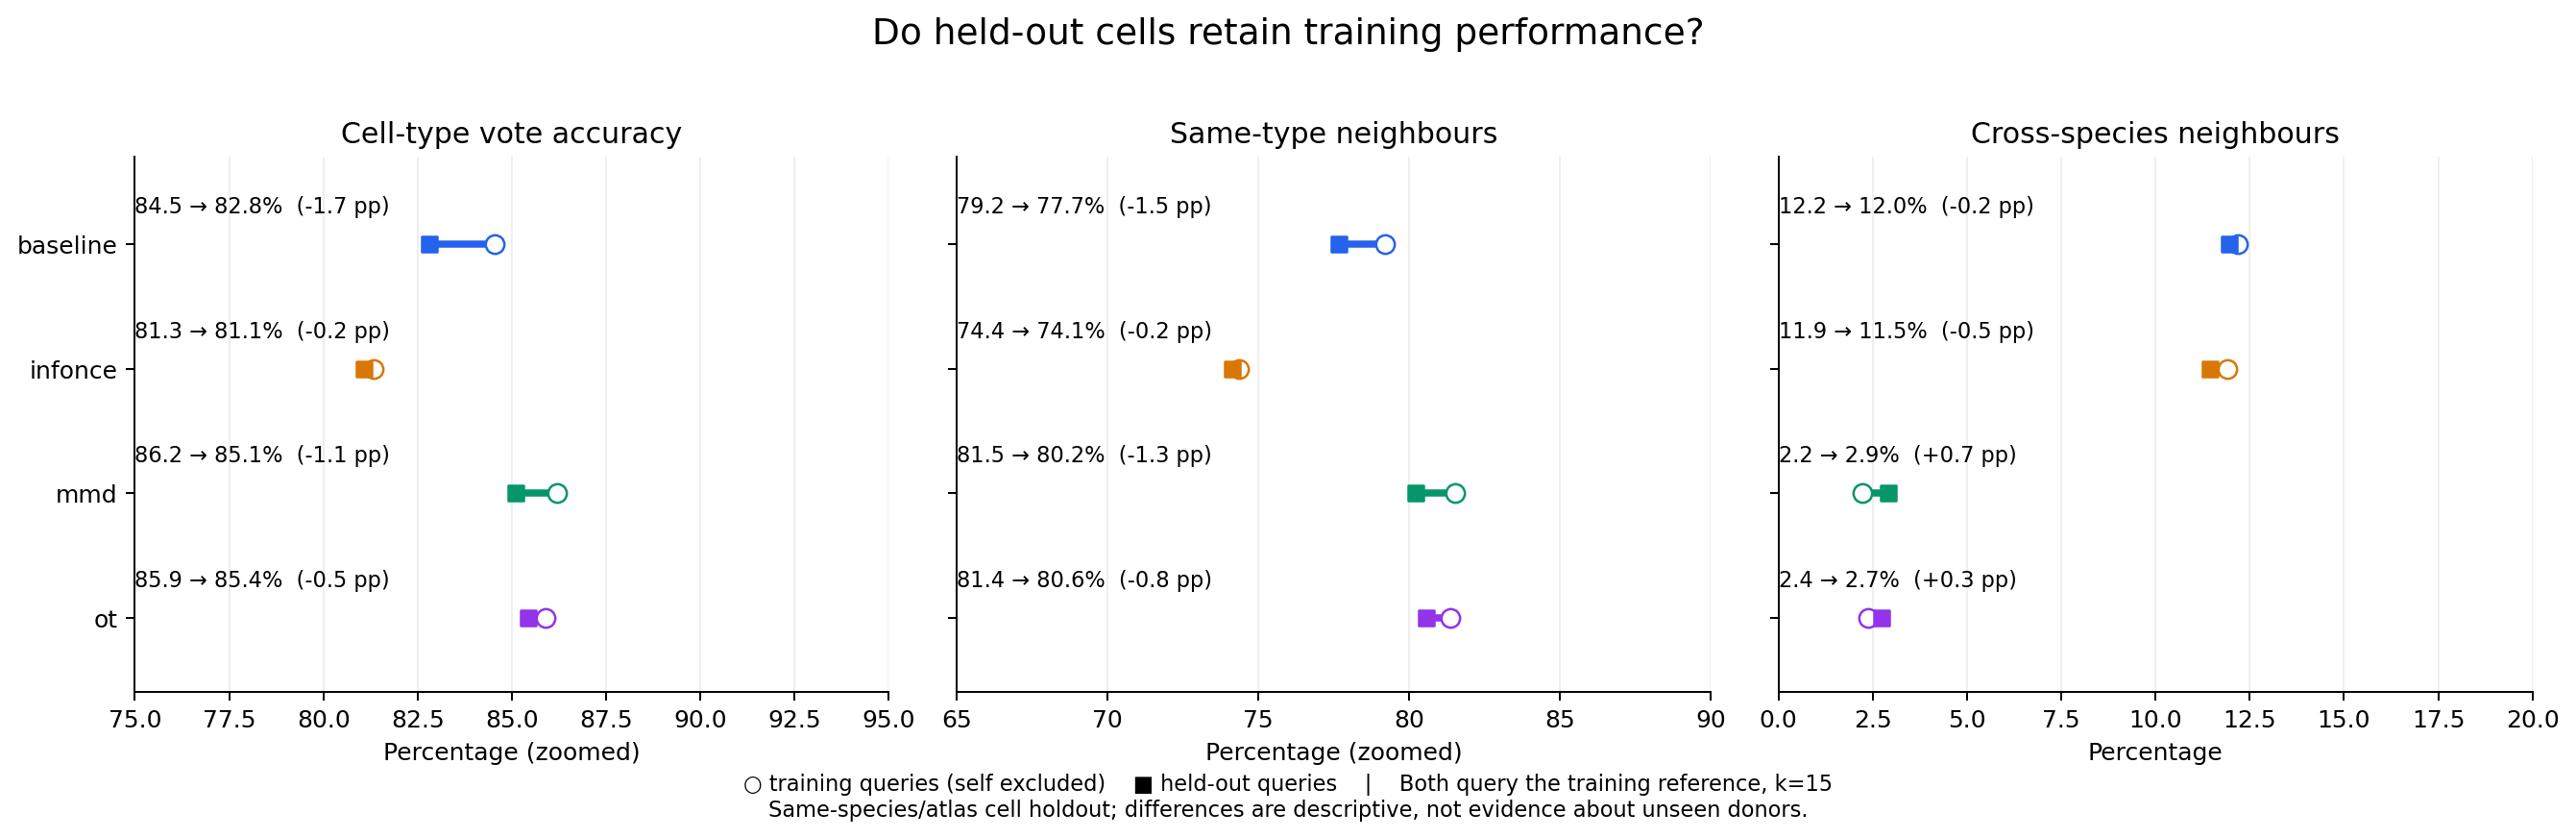

In [5]:
display(split_counts.rename(index=SPECIES, columns={'train': 'Training cells', 'test': 'Held-out cells'})
        .style.format('{:,}'))
accuracy = pd.DataFrame({
    'Training accuracy (%)': 100 * overall.train_label_vote_accuracy,
    'Held-out accuracy (%)': 100 * overall.test_label_vote_accuracy,
    'Accuracy drop (pp)': -overall.gap_pp_label_vote_accuracy,
    'Held-out cross-species neighbours (%)': 100 * overall.test_species_mixing_fraction,
}).rename(index=NAMES)
display(accuracy.style.format('{:.2f}'))
saved_figure(HOLDOUT / 'diagnostics/generalization_summary.png')

In [6]:
info, base = overall.loc['infonce'], overall.loc['baseline']
info_species = generalization.loc[(generalization.dimension == 'species') & (generalization.trial == 'infonce')]
assert overall.gap_pp_label_vote_accuracy.abs().idxmin() == 'infonce'
assert info_species.test_queries.sum() == test_n
max_species_drop = -info_species.gap_pp_label_vote_accuracy.min()
display(Markdown(f"""
**Result.** InfoNCE accuracy changed from **{100*info.train_label_vote_accuracy:.2f}%**
on training queries to **{100*info.test_label_vote_accuracy:.2f}%** on held-out queries:
a drop of **{-info.gap_pp_label_vote_accuracy:.2f} percentage points**, the smallest observed
average gap. Its largest species-level accuracy drop was **{max_species_drop:.2f} points**.
Same-label neighbour agreement also barely changed, from
**{100*info.train_label_same_neighbor_fraction:.2f}%** to **{100*info.test_label_same_neighbor_fraction:.2f}%**.

InfoNCE retained **{100*info.test_species_mixing_fraction:.2f}%** cross-species neighbours
on test queries, close to the baseline's **{100*base.test_species_mixing_fraction:.2f}%**.
The supervised baseline still had higher absolute held-out accuracy
({100*base.test_label_vote_accuracy:.2f}% versus {100*info.test_label_vote_accuracy:.2f}%).

**What this adds to the report.** InfoNCE's representation carries over to cells excluded
from the whole fitted pipeline with little average deterioration. Its weaker agreement
with fine annotations is already present on training cells, rather than appearing as a
large test-performance loss. This adds evidence of generalization within these atlases.
A small gap alone does not establish that a method is the best predictor.
"""))


**Result.** InfoNCE accuracy changed from **81.34%**
on training queries to **81.09%** on held-out queries:
a drop of **0.25 percentage points**, the smallest observed
average gap. Its largest species-level accuracy drop was **0.44 points**.
Same-label neighbour agreement also barely changed, from
**74.37%** to **74.13%**.

InfoNCE retained **11.45%** cross-species neighbours
on test queries, close to the baseline's **11.96%**.
The supervised baseline still had higher absolute held-out accuracy
(82.82% versus 81.09%).

**What this adds to the report.** InfoNCE's representation carries over to cells excluded
from the whole fitted pipeline with little average deterioration. Its weaker agreement
with fine annotations is already present on training cells, rather than appearing as a
large test-performance loss. This adds evidence of generalization within these atlases.
A small gap alone does not establish that a method is the best predictor.


### Accuracy and integration answer different questions

MMD and OT also retain high held-out accuracy. Their much lower species mixing
means this does not, by itself, demonstrate a shared cross-species representation.
This repeats the central evaluation tradeoff in the original report.

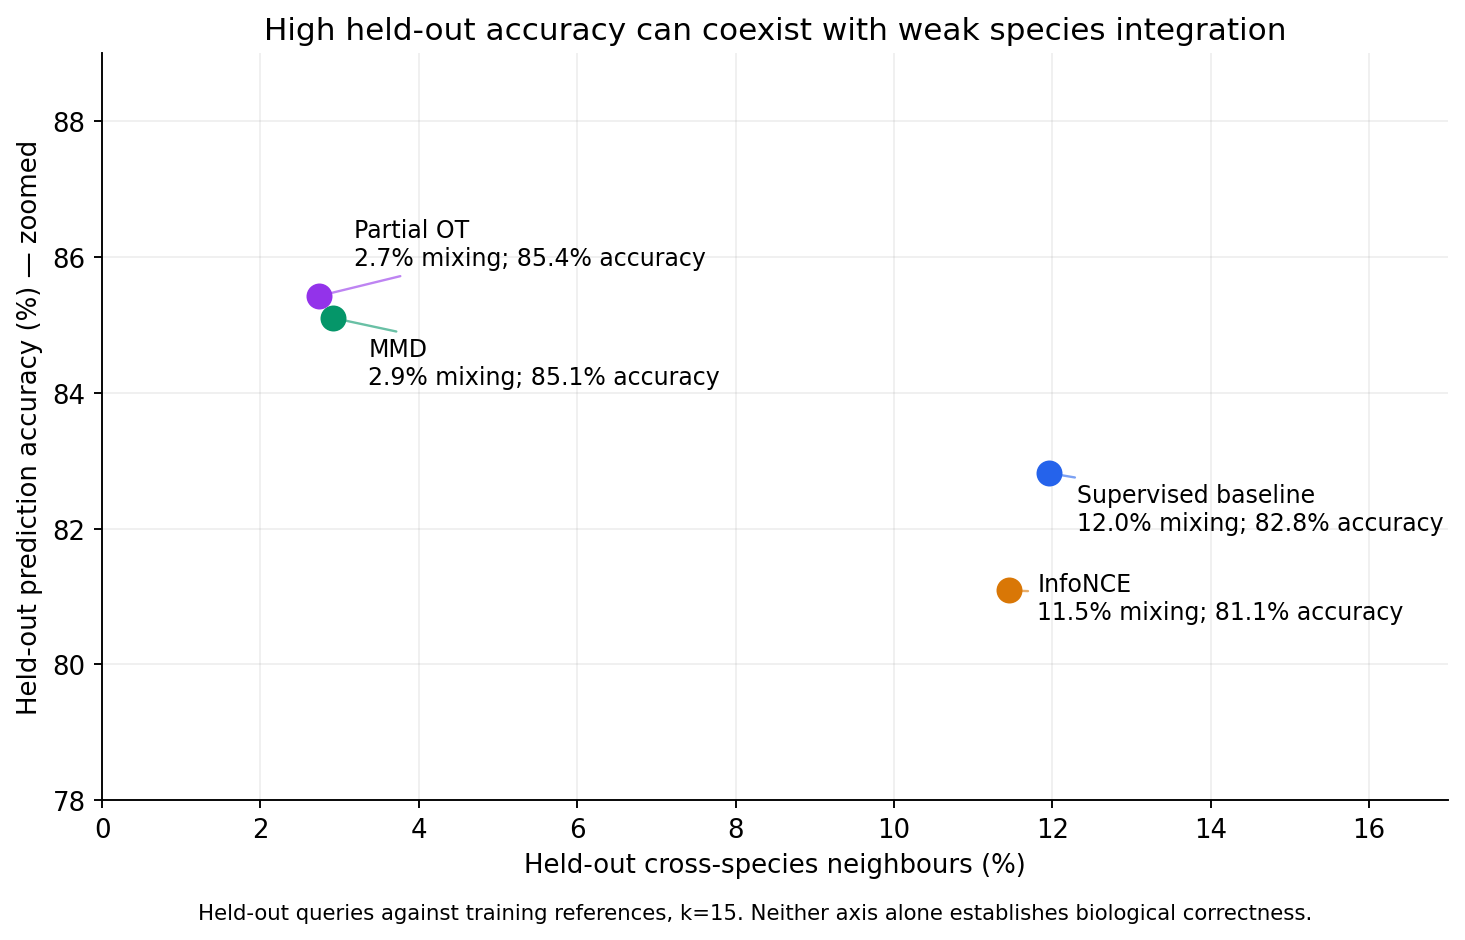

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.4))
offsets = {'baseline': (12, -24), 'infonce': (12, -12), 'mmd': (15, -28), 'ot': (15, 13)}
for trial in TRIALS:
    row = overall.loc[trial]
    x, y = 100 * row.test_species_mixing_fraction, 100 * row.test_label_vote_accuracy
    ax.scatter(x, y, color=COLORS[trial], s=100, zorder=3)
    ax.annotate(f'{NAMES[trial]}\n{x:.1f}% mixing; {y:.1f}% accuracy', (x, y),
                xytext=offsets[trial], textcoords='offset points', fontsize=10,
                arrowprops={'arrowstyle': '-', 'color': COLORS[trial], 'alpha': .6})
ax.set(xlabel='Held-out cross-species neighbours (%)', ylabel='Held-out prediction accuracy (%) — zoomed',
       xlim=(0, 17), ylim=(78, 89), title='High held-out accuracy can coexist with weak species integration')
ax.grid(alpha=.2)
fig.text(.5, -.015, 'Held-out queries against training references, k=15. Neither axis alone establishes biological correctness.',
         ha='center', fontsize=9)
fig.tight_layout()
save_figure(fig, 'heldout_accuracy_and_integration')

### Does the average hide a species-specific gap?

The left panels show held-out scores; the right panels show test minus training
scores in percentage points. Negative gaps indicate deterioration. Test counts are
shown because species are sampled unevenly. In particular, zebrafish has only 219
test cells. InfoNCE's small average gap is accompanied by small species-level gaps.

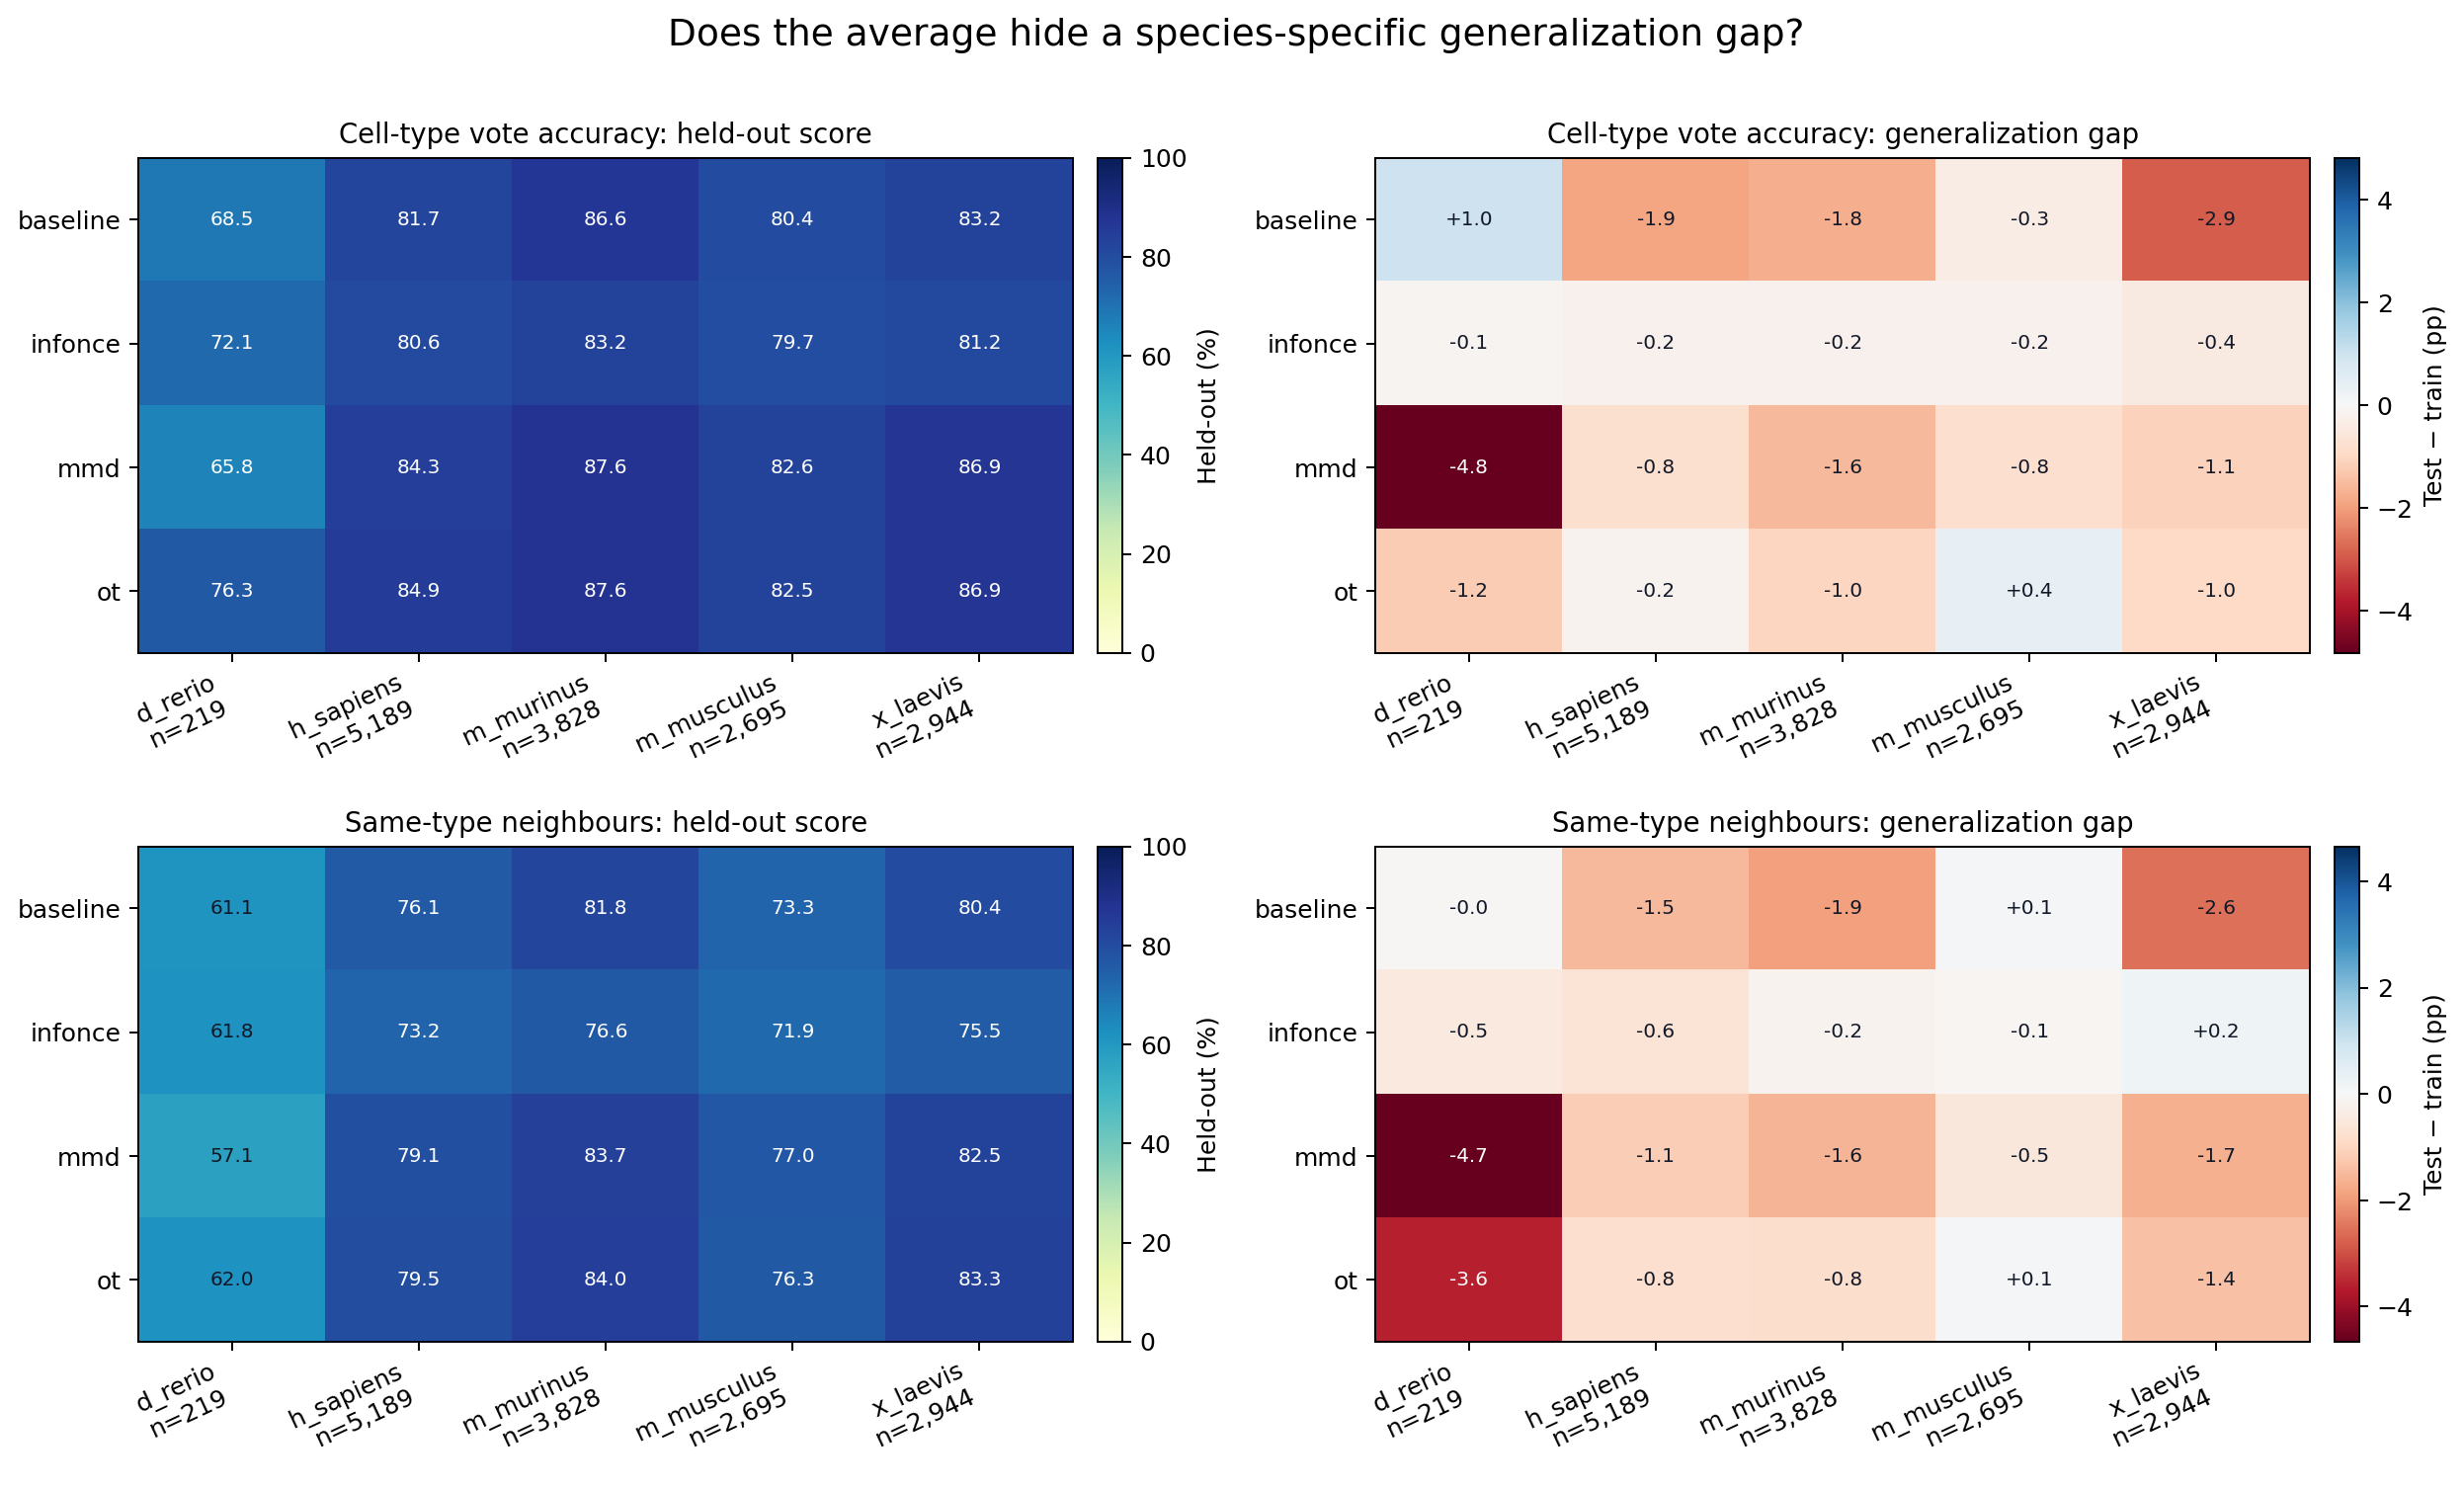

,Held-out cells,Held-out accuracy (%),Test minus train (pp)
group,,,
Human,"5,189",80.59,-0.21
Mouse lemur,"3,828",83.15,-0.20
Mouse,"2,695",79.70,-0.21
Frog,"2,944",81.22,-0.44
Zebrafish,219,72.15,-0.15


In [8]:
species_rows = generalization.loc[generalization.dimension == 'species'].copy()
for trial in TRIALS:
    subset = species_rows.loc[species_rows.trial == trial].set_index('group')
    assert subset.index.is_unique and set(subset.index) == set(SPECIES)
    np.testing.assert_array_equal(subset.loc[list(SPECIES), 'test_queries'], split_counts.test)
saved_figure(HOLDOUT / 'diagnostics/generalization_by_species.png')
display(info_species.set_index('group').loc[list(SPECIES),
    ['test_queries', 'test_label_vote_accuracy', 'gap_pp_label_vote_accuracy']]
    .rename(index=SPECIES, columns={'test_queries': 'Held-out cells',
        'test_label_vote_accuracy': 'Held-out accuracy (%)', 'gap_pp_label_vote_accuracy': 'Test minus train (pp)'})
    .assign(**{'Held-out accuracy (%)': lambda x: 100*x['Held-out accuracy (%)']})
    .style.format({'Held-out cells': '{:,.0f}', 'Held-out accuracy (%)': '{:.2f}', 'Test minus train (pp)': '{:+.2f}'}))

### Where do cell-type gaps remain?

Small overall gaps do not mean every cell type performs equally well. This view
shows up to 20 types with at least 50 held-out cells, ranked by the largest observed
accuracy drop in any method. Types are pooled across species. Selection highlights
observed weaknesses; it is not a significance test or an estimate from independent
biological replicates. All groups remain available in the saved CSV.

The [existing interactive error explorer](../../out/human_monkey_mouse_frog_fish_jax_cell_holdout/diagnostics/heldout_errors.html)
lets you filter held-out cells by method, species, true cell type and incorrect votes.
It uses the saved training-fitted UMAP coordinates and observation-level hover information.

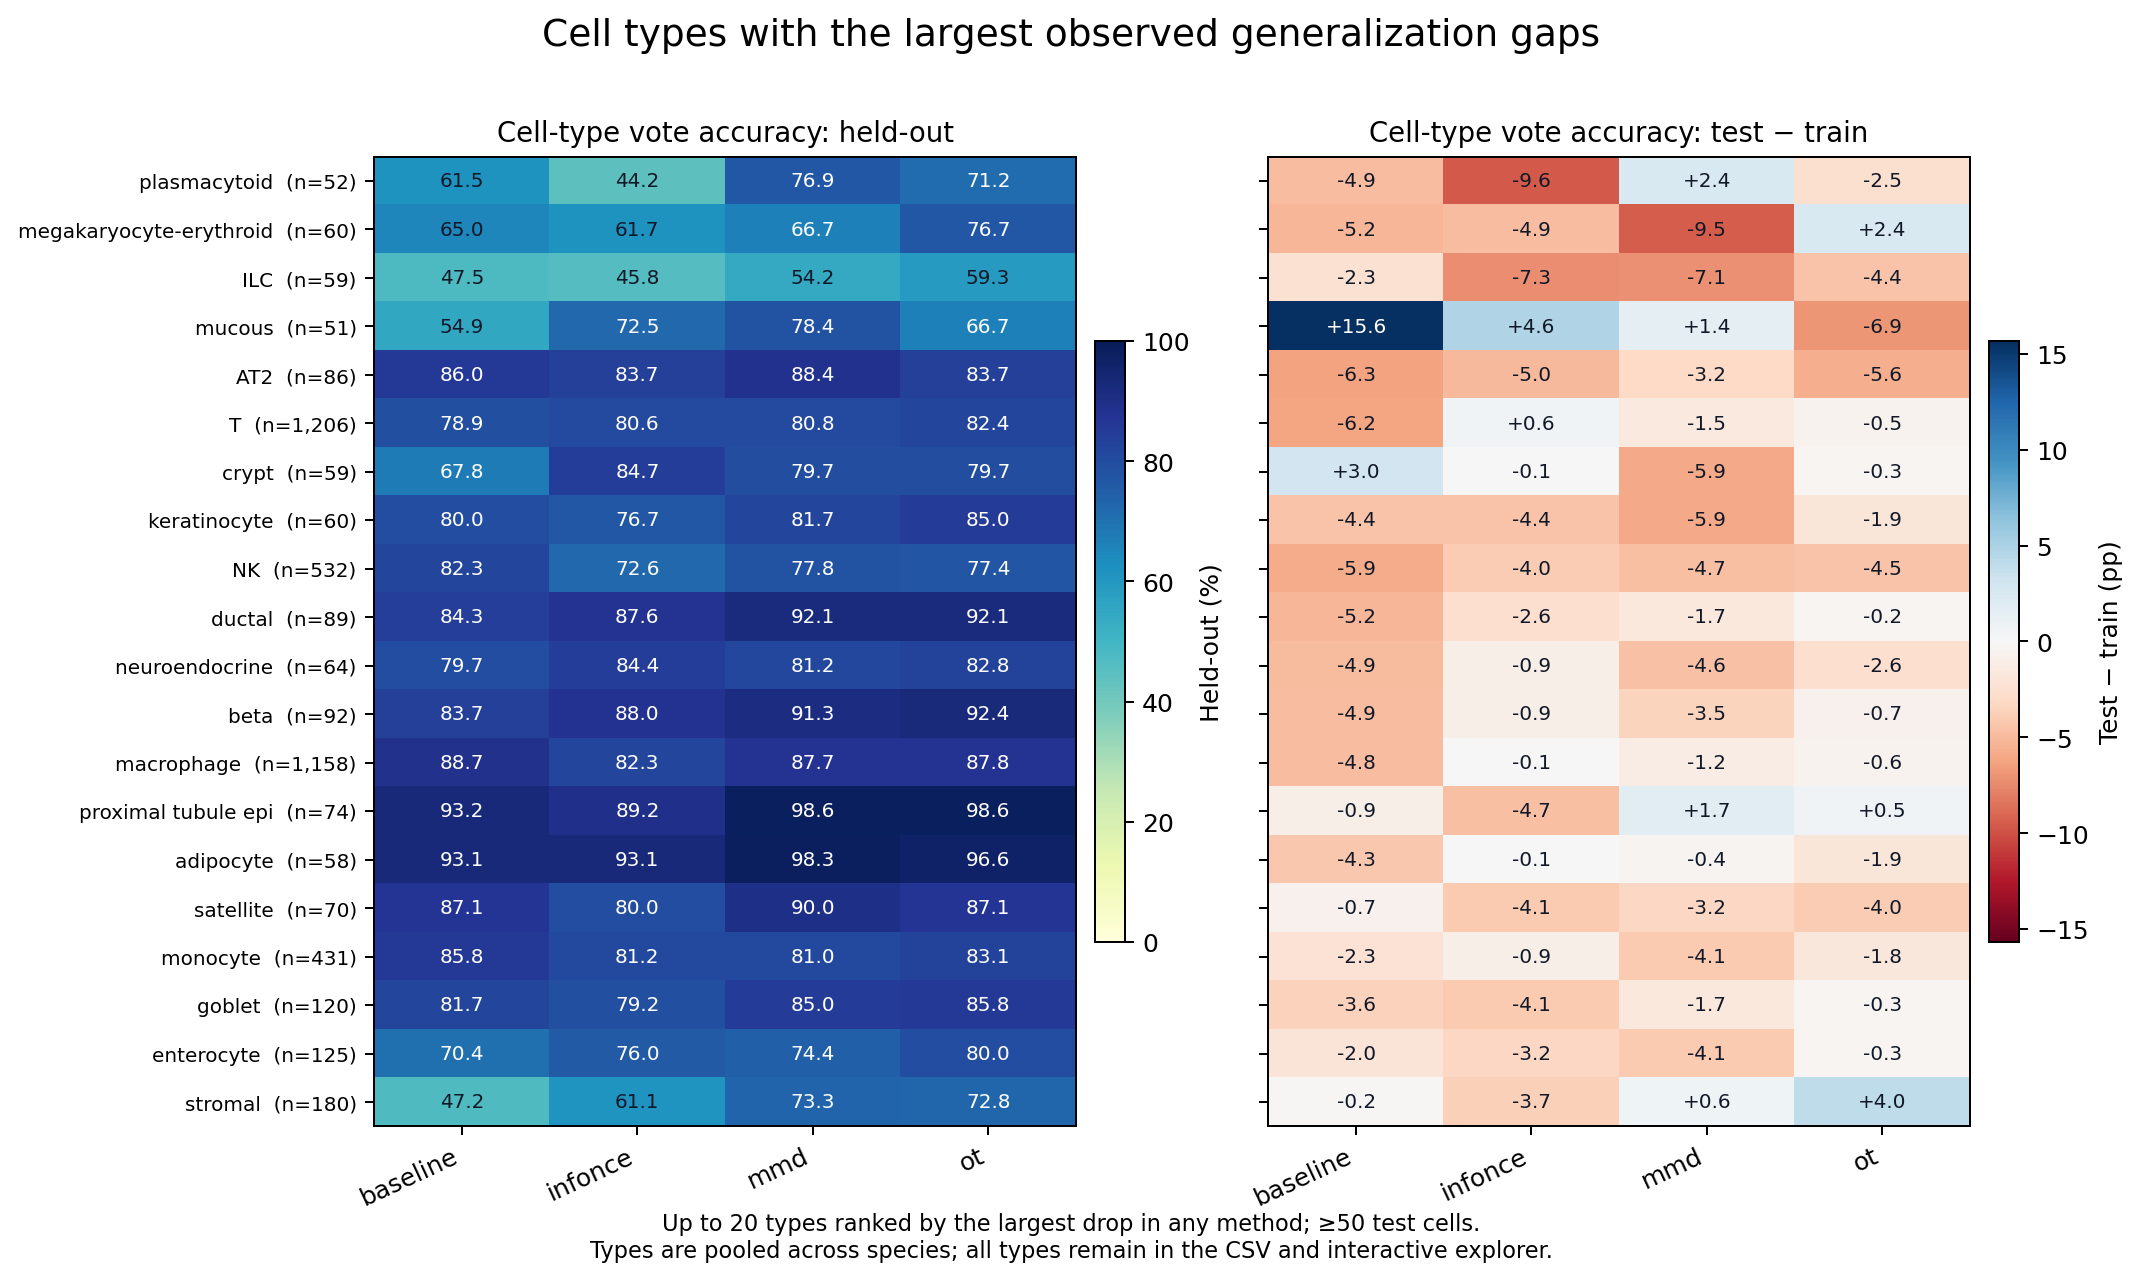

In [9]:
saved_figure(HOLDOUT / 'diagnostics/generalization_by_cell_type.png')

## Scientific thresholds and execution success

Both cloud experiments completed their requested stages. None of the label-free
methods met all three preset comparison thresholds: fixed triplet loss, same-label
neighbour agreement and species mixing, each relative to its supervised baseline.

These thresholds evaluate a different question from the size of the held-out gap.
The larger InfoNCE run missed the label-agreement threshold; the holdout InfoNCE
run missed the triplet-loss threshold. Its small train/test gap is still positive
generalization evidence. The triplet and label metrics also retain the annotation-based
evaluation limitations discussed in the original report.

In [10]:
checks = []
for name, frame in [('Larger full-data run', larger), ('Cell-holdout run', holdout_training)]:
    result = acceptance[name]
    assert not result['success'] and result['passing_label_free_trials'] == []
    thresholds = result['thresholds']
    for trial in TRIALS[1:]:
        row = frame.loc[trial]
        flags = [row.fixed_triplet_margin_loss <= thresholds['fixed_triplet_margin_loss_max'],
                 row.label_same_neighbor_fraction >= thresholds['label_same_neighbor_fraction_min'],
                 row.species_mixing_fraction >= thresholds['species_mixing_fraction_min']]
        assert flags == [bool(row[k]) for k in ('passes_loss', 'passes_label_same_neighbor', 'passes_species_mixing')]
        checks.append([name, NAMES[trial], *['Pass' if value else 'Below target' for value in flags]])
display(pd.DataFrame(checks, columns=['Experiment', 'Method', 'Triplet loss', 'Label agreement', 'Species mixing'])
        .set_index(['Experiment', 'Method']))

Triplet loss Label agreement Species mixing
Experiment           Method                                                 
Larger full-data run InfoNCE             Pass    Below target           Pass
                     MMD         Below target            Pass   Below target
                     Partial OT          Pass            Pass   Below target
Cell-holdout run     InfoNCE     Below target            Pass           Pass
                     MMD         Below target            Pass   Below target
                     Partial OT          Pass            Pass   Below target

## What the report can now conclude

The new experiments strengthen the case for InfoNCE as a useful alternative to
cell-type-supervised fine-tuning. Its strong species integration persists when frog
and zebrafish are added to the three mammals and when the model architecture is
enlarged. The strict holdout experiment additionally shows that the learned representation
retains most of its training performance when applied to previously unseen cells
from the same five input atlases. Across both experiments, MMD and partial OT retain
strong annotation agreement but produce substantially weaker overall species integration.

The results therefore address part of the report's narrow biological scope (§5.4 and
§6.2.2) and add a new test of generalization beyond fitted observations. They do not
isolate the effect of embedding dimensions or establish a scaling law (§5.3).
Fine-tuning duration also differs: 20 epochs in the original report, versus 30
completed epochs per method in the two new experiments.
The supervised baseline still has higher absolute held-out prediction accuracy than
InfoNCE, so the new result supports consistency rather than a universal performance advantage.

The central biological validation problem remains (§6.2.3). A species-stratified
cell split within existing atlases does not test transfer to independent atlases,
unseen donors or unseen species. Matching annotations or mixing species cannot
establish that cross-species correspondences are biologically correct. Both
experiments used one seed, and cell-level scores do not provide independent
biological replication. Independent datasets, conserved marker programmes and
functional evidence remain important next steps.

## Sources and local execution record

Numerical claims above come from saved metrics, with configuration read from saved
metadata. The original report's training duration is author-confirmed; the two new
experiments' epoch counts are checked against their saved histories. The notebook
also checks split counts, training/test metric consistency and threshold flags.
The input manifest below records the bytes used by this rendering.
It describes this local report, not a rerun of either scientific experiment.

- [Original report](../../COMP9991_Report%20%289%29.pdf)
- [Larger experiment comparison](../../out/downloaded_human_monkey_mouse_frog_fish_jax_gpu_exact/comparison.csv)
- [Held-out group scores](../../out/human_monkey_mouse_frog_fish_jax_cell_holdout/diagnostics/generalization.csv)
- [Observation-level held-out scores](../../out/human_monkey_mouse_frog_fish_jax_cell_holdout/diagnostics/test_cells.csv.gz)
- [Regenerated figures and provenance](../../out/five_species_experiment_report/)
- [Epoch counts and source histories](../../out/five_species_experiment_report/epoch_audit.csv)

In [11]:
model_libraries = sorted(set(sys.modules) & {'jax', 'flax', 'torch', 'tensorflow', 'scanpy', 'umap'})
assert not model_libraries, f'Model/embedding libraries were unexpectedly imported: {model_libraries}'
for relative, expected in inputs.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected['sha256'], relative
manifest = {'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'execution': 'Local rendering from saved CSV/JSON/PNG artifacts',
    'training_performed': False, 'inference_performed': False, 'neighbors_computed': False,
    'umap_fitted': False, 'cloud_accessed': False, 'model_libraries_loaded': model_libraries,
    'original_inputs_unchanged': True, 'inputs': inputs,
    'new_experiment_epochs_verified_from_histories': True,
    'original_report_training': original_training,
    'pretraining_epochs_completed': pretraining_completed,
    'fine_tuning_epochs_completed': finetuning_completed,
    'epoch_audit': epoch_audit.to_dict(orient='records'),
    'versions': {'python': sys.version.split()[0], 'numpy': np.__version__,
                 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__}}
(REPORT / 'report_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')
display(Markdown(f'**Local report completed.** {len(inputs)} saved inputs were checked and remain unchanged. '
                 'No training, inference, neighbour search, UMAP fitting or cloud access was performed.'))
display(pd.DataFrame.from_dict(inputs, orient='index').rename_axis('Source artifact'))

**Local report completed.** 46 saved inputs were checked and remain unchanged. No training, inference, neighbour search, UMAP fitting or cloud access was performed.

,sha256,size
Source artifact,,
out/human_monkey_mouse_benchmark_walkthrough/comparison.csv,2cf58d219f6ba0300d08503a6e16ffd046a06ecb71e334...,1487
out/downloaded_human_monkey_mouse_frog_fish_jax_gpu_exact/comparison.csv,236c43abe9aaab2afd3e0a27a16791d5f3079508bce43c...,1479
out/human_monkey_mouse_frog_fish_jax_cell_holdout/run/comparison.csv,63e60ac7b08f42c3e4668cac2553ec5e61732111a3f801...,1476
out/human_monkey_mouse_benchmark_walkthrough/shared/artifact_metadata.json,33beed9cc2ba871bd6703a5f74e6aa198fea0087d08ac7...,398
out/human_monkey_mouse_benchmark_walkthrough/infonce/run_summary.json,772d4e1df60a7aedb60b6962cb01ceb7651432eda13535...,2092
out/downloaded_human_monkey_mouse_frog_fish_jax_gpu_exact/experiment_record.json,3c4cec27ef8caa139f7fd679e2b3baa2974c9a40b528cd...,25435
out/downloaded_human_monkey_mouse_frog_fish_jax_gpu_exact/baseline/metric_orbax/checkpoints/epoch_0030/metadata.json,e3b0fdd8e2811b97cfb56f2ee3b653b280f8b5fb34ac25...,791
out/human_monkey_mouse_frog_fish_jax_cell_holdout/experiment_config.json,e1ffdf605523af0ca7fe771c5e959ab59416a692f0f648...,344
out/human_monkey_mouse_frog_fish_jax_cell_holdout/foundation/baseline/metric_orbax/checkpoints/epoch_0030/metadata.json,f683b46cfb68512597890672f9e3f1fb81ce91fe710d12...,791
